In [1]:
import jax
import jax.numpy as jnp

import matplotlib.pyplot as plt

from agfx.gym import create_state, from_amat
from agfx.special.linear_gaussian import sample_linear_gaussian
from agfx.rewards import create_log_reward, LogRewardType 
from agfx.training import train, LossType
from agfx.policies import GFlowNet

In [2]:
num_nodes = 5
bs = 64
dmid = 64

iterations = int(1e4)
logr_t = LogRewardType.BIC
loss_t = LossType.TB

seeds = [42, 84, 126]

reward_seed = 43

In [3]:
reward_key = jax.random.key(reward_seed)
# Simulate the data (which is needed for certain reward functions)
data, dir_amat, bidir_amat, *_ = sample_linear_gaussian(
    reward_key, num_nodes, num_samples=20
)
true_graph = from_amat((dir_amat + bidir_amat)[None])

In [4]:
losses_per_seed = []

for seed in seeds:
    key = jax.random.key(seed)
    state = create_state(bs, num_nodes)
    # Create the GFlowNet
    gfn = GFlowNet(num_nodes, dmid, seed=seed)
    # Create the reward function
    logr = create_log_reward(logr_t, data, true_graph)

    _, losses = train(gfn, state, key, logr, iterations, loss_t)

    losses_per_seed.append(losses)

100%|██████████| 10000/10000 [00:52<00:00, 189.55it/s, loss=1.47e-01]


In [5]:
from mpl_preamble import *

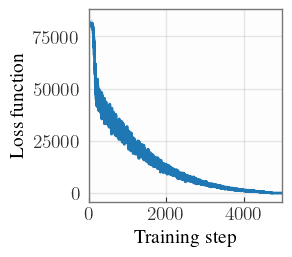

In [6]:
losses_per_seed = jnp.array(losses_per_seed)
mu = losses_per_seed.mean(axis=0)
std = losses_per_seed.std(axis=0)

xs = jnp.arange(len(mu)) + 1
plt.plot(xs, mu)
plt.fill_between(xs, mu-std, mu+std, alpha=.5)

plt.ylabel("Loss function")
plt.xlabel("Training step")

plt.xlim(0, 5000)
plt.savefig("figures/loss_functions.pdf", bbox_inches="tight")